# 스프린트 미션 2

### Hotel Booking Demand Datasets 분석
#### 호텔 예약 취소 원인 분석 & 취소율 감소 방안 검토 ####

목표
1. 예약 취소가 자주 발생하는 원인 분석
2. 분석한 취소 원인 해결을 위한 방안 탐색


## 1. 데이터 불러오기 ##

- hotel_data_modified.csv 파일 불러오기
- 국가 코드 정리하기

In [77]:
# 파일 불러오기
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

hotel_df = pd.read_csv('./hotel_data_modified.csv')
hotel_df.head(3)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,reserved_room_type,assigned_room_type,booking_changes,agent,company,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,C,C,3,NaN,NaN,0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,C,C,4,NaN,NaN,0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,A,C,0,NaN,NaN,0,0,0,Check-Out,2015-07-02


In [78]:
#데이터프레임 크기 확인 : 몇건의 예약이 있는지, 몇가지의 칼럼이 있는지 확인
hotel_df.shape

(119390, 29)

In [79]:
#데이터프레임 종합적인 정보 확인
hotel_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 29 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [80]:
#데이터프레임의 모든 컬럼의 이름 확인
hotel_df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'agent', 'company',
       'days_in_waiting_list', 'required_car_parking_spaces',
       'total_of_special_requests', 'reservation_status',
       'reservation_status_date'],
      dtype='object')

In [81]:
#국가코드의 구성 및 고유값 갯수 확인
hotel_df['country'].head(5), hotel_df['country'].nunique(dropna=False)


(0    PRT
 1    PRT
 2    GBR
 3    GBR
 4    GBR
 Name: country, dtype: object,
 178)

In [82]:
num_cols = hotel_df.select_dtypes(include=['int64', 'float64']).columns
cat_cols = hotel_df.select_dtypes(include=['object']).columns

print("숫자형 컬럼 개수:", len(num_cols))
print("범주형 컬럼 개수:", len(cat_cols))

num_cols, cat_cols

숫자형 컬럼 개수: 19
범주형 컬럼 개수: 10


(Index(['is_canceled', 'lead_time', 'arrival_date_year',
        'arrival_date_week_number', 'arrival_date_day_of_month',
        'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
        'babies', 'is_repeated_guest', 'previous_cancellations',
        'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company',
        'days_in_waiting_list', 'required_car_parking_spaces',
        'total_of_special_requests'],
       dtype='object'),
 Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
        'distribution_channel', 'reserved_room_type', 'assigned_room_type',
        'reservation_status', 'reservation_status_date'],
       dtype='object'))

In [83]:
# 범주형: 카테고리 수 확인
hotel_df[cat_cols].nunique().sort_values()

hotel                        2
reservation_status           3
meal                         5
distribution_channel         5
market_segment               8
reserved_room_type          10
arrival_date_month          12
assigned_room_type          12
country                    177
reservation_status_date    926
dtype: int64

In [84]:
# 숫자형: 값 종류 수 확인(상수에 가까운 컬럼 체크)
hotel_df[num_cols].nunique().sort_values()

is_canceled                         2
is_repeated_guest                   2
arrival_date_year                   3
required_car_parking_spaces         5
children                            5
babies                              5
total_of_special_requests           6
adults                             14
previous_cancellations             15
stays_in_weekend_nights            17
booking_changes                    21
arrival_date_day_of_month          31
stays_in_week_nights               35
arrival_date_week_number           53
previous_bookings_not_canceled     73
days_in_waiting_list              128
agent                             333
company                           352
lead_time                         479
dtype: int64

In [85]:
pd.crosstab(hotel_df['is_canceled'], hotel_df['reservation_status'])

reservation_status,Canceled,Check-Out,No-Show
is_canceled,,,
0,0,75166,0
1,43017,0,1207


In [86]:
#국가코드 정리
country_codes = {
    "Afghanistan": "AFG",
    "Albania": "ALB",
    "Algeria": "DZA",
    "American Samoa": "ASM",
    "Andorra": "AND",
    "Angola": "AGO",
    "Anguilla": "AIA",
    "Antarctica": "ATA",
    "Antigua and Barbuda": "ATG",
    "Argentina": "ARG",
    "Armenia": "ARM",
    "Aruba": "ABW",
    "Australia": "AUS",
    "Austria": "AUT",
    "Azerbaijan": "AZE",
    "Bahamas": "BHS",
    "Bahrain": "BHR",
    "Bangladesh": "BGD",
    "Barbados": "BRB",
    "Belarus": "BYL",
    "Belgium": "BEL",
    "Belize": "BLZ",
    "Benin": "BEN",
    "Bermuda": "BMU",
    "Bhutan": "BTN",
    "Bolivia": "BOL",
    "Bosnia and Herzegovina": "BIH",
    "Botswana": "BWA",
    "Brazil": "BRA",
    "Brunei Darussalam": "BRN",
    "Bulgaria": "BGR",
    "Burkina Faso": "BFA",
    "Burundi": "BDI",
    "Cabo Verde": "CPV",
    "Cambodia": "KHM",
    "Cameroon": "CMR",
    "Canada": "CAN",
    "Cayman Islands": "CYM",
    "Central African Republic": "CAF",
    "Chad": "TCD",
    "Chile": "CHL",
    "China": "CHN",
    "Colombia": "COL",
    "Congo (Democratic Republic)": "COD",
    "Congo (Republic)": "COG",
    "Costa Rica": "CRI",
    "Cote d'Ivoire": "CIV",
    "Croatia": "HRV",
    "Cuba": "CUB",
    "Cyprus": "CYP",
    "Czechia": "CZE",
    "Denmark": "DNK",
    "Djibouti": "DJI",
    "Dominica": "DMA",
    "Dominican Republic": "DOM",
    "Ecuador": "ECU",
    "Egypt": "EGY",
    "El Salvador": "SLV",
    "Estonia": "EST",
    "Ethiopia": "ETH",
    "Fiji": "FJI",
    "Finland": "FIN",
    "France": "FRA",
    "Germany": "DEU",
    "Ghana": "GHA",
    "Greece": "GRC",
    "Hong Kong": "HKG",
    "Hungary": "HUN",
    "Iceland": "ISL",
    "India": "IND",
    "Indonesia": "IDN",
    "Iran": "IRN",
    "Iraq": "IRQ",
    "Ireland": "IRL",
    "Israel": "ISR",
    "Italy": "ITA",
    "Jamaica": "JAM",
    "Japan": "JPN",
    "Jordan": "JOR",
    "Kazakhstan": "KAZ",
    "Kenya": "KEN",
    "Korea (North)": "PRK",
    "Korea (South)": "KOR",
    "Kuwait": "KWT",
    "Malaysia": "MYS",
    "Mexico": "MEX",
    "Netherlands": "NLD",
    "New Zealand": "NZL",
    "Norway": "NOR",
    "Pakistan": "PAK",
    "Philippines": "PHL",
    "Poland": "POL",
    "Portugal": "PRT",
    "Qatar": "QAT",
    "Russian Federation": "RUS",
    "Saudi Arabia": "SAU",
    "Singapore": "SGP",
    "Spain": "ESP",
    "Switzerland": "CHE",
    "Taiwan": "TWN",
    "Thailand": "THA",
    "Turkey": "TUR",
    "Ukraine": "UKR",
    "United Arab Emirates": "ARE",
    "United Kingdom": "GBR",
    "United States": "USA",
    "Vietnam": "VNM"
}

In [87]:
#국가코드의 타입 확인
type(country_codes)

dict

## 2. 데이터 전처리 ##

### 2-1. 결측값 확인 ###

In [88]:
#데이터의 결측치 확인 : 데이터들 중 비어있는 값들을 확인해서 문제가 발생할 수 있는 데이터 확인
missing = (hotel_df.isna().mean().sort_values(ascending=False) * 100).round(2)
missing


company                           94.31
agent                             13.69
country                            0.41
children                           0.00
hotel                              0.00
is_repeated_guest                  0.00
reservation_status                 0.00
total_of_special_requests          0.00
required_car_parking_spaces        0.00
days_in_waiting_list               0.00
booking_changes                    0.00
assigned_room_type                 0.00
reserved_room_type                 0.00
previous_bookings_not_canceled     0.00
previous_cancellations             0.00
market_segment                     0.00
distribution_channel               0.00
is_canceled                        0.00
meal                               0.00
babies                             0.00
adults                             0.00
stays_in_week_nights               0.00
stays_in_weekend_nights            0.00
arrival_date_day_of_month          0.00
arrival_date_week_number           0.00


In [89]:
#결측치, 이상치 점검
(hotel_df.isna().mean().sort_values(ascending=False) * 100).round(2).head(10)

company                        94.31
agent                          13.69
country                         0.41
children                        0.00
hotel                           0.00
is_repeated_guest               0.00
reservation_status              0.00
total_of_special_requests       0.00
required_car_parking_spaces     0.00
days_in_waiting_list            0.00
dtype: float64

- 'company' : 결측치가 94.31%로 너무 적어 분석에서 제외
- 'agent' : 13.69%의 결측치가 '없음'을 의미할 수 있으니 결측 처리 후 사용
- 'country' : 결측치가 0.41%로 매우 적으니 결측값만 제외하고 사용

In [90]:
#정수값&실수값 이상 있는지 확인
num_cols = hotel_df.select_dtypes(include=['int64','float64']).columns

hotel_df[num_cols].describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,8.000000,5.000000


In [91]:
#1. 숙박일수 합이 0인 예약이 있는지
total_nights = hotel_df['stays_in_weekend_nights'] + hotel_df['stays_in_week_nights']
test_01 = (total_nights == 0).sum()

#2. 성인 수가 0인데 예약이 있는 경우(이상치일 수 있음)
test_02 = (hotel_df['adults'] == 0).sum()

#3. children 결측 확인(있으면 0으로 채울지 결정)
test_03 = hotel_df['children'].isna().sum()

print(test_01)
print(test_02)
print(test_03)

715
403
4


- 숙박일수 합이 0일 = 715건 : 바로 삭제하지는 않고 어떤 경우에 이렇게 된건지 후에 확인
- adults가 0인 예약 : 성인 0명은 비정상적이라 후에 확인
- children의 결측값 : 4건으로 매우 적으니 0으로 데이터를 수정 후 진행

In [92]:
# 숙박일수 0인 예약건이 어떻게 된것인지 확인하기

# total_nights 만들기
total_nights = hotel_df['stays_in_weekend_nights'] + hotel_df['stays_in_week_nights']

# 숙박일수 0인 예약만 필터링
zero_nights_df = hotel_df[total_nights == 0].copy()

# 건수 & 취소율 확인
print("숙박일수 0인 예약 건수:", len(zero_nights_df))
print("숙박일수 0인 예약 취소 건수:", zero_nights_df['is_canceled'].sum())
print("숙박일수 0인 예약 취소율:", round(zero_nights_df['is_canceled'].mean(), 4))

# (참고) 전체 취소율과 비교
print("\n전체 예약 취소율:", round(hotel_df['is_canceled'].mean(), 4))



숙박일수 0인 예약 건수: 715
숙박일수 0인 예약 취소 건수: 35
숙박일수 0인 예약 취소율: 0.049

전체 예약 취소율: 0.3704


### 2-2. 결측값들 처리(해결)하기 ###

- 숙박일수가 0건인 경우

숙박일수가 0건인 건들은 715건 중 취소건은 35건으로 4.9%이다. 값이 매우 작아 데이터를 무시하거나 삭제할 수도 있지만, 
특이 케이스일 수 있으니 데이터는 그대로 유지하기로 결정


- 결측값들 수정하기

children의 결측값 -> 0으로 작성
country의 결측값 -> Unknown으로 작성
agent -> Unknown으로 작성 (원래 agent의 값들은 숫자이지만, 추후 의미가 생길 수 있으니 우선 unknown으로 작성)
company -> Unknown으로 작성(결측값이 많지만, 삭제보다는 일단 언노운 값을 넣어 유지)



In [93]:
df = hotel_df.copy() #원본 살려두기

# 1) children 결측값 -> 0
df['children'] = df['children'].fillna(0)

# 2) country 결측값 -> 'Unknown'
df['country'] = df['country'].fillna('Unknown')

# 3) agent 결측값 -> 'Unknown'
# agent는 ID(숫자)지만 결측이 의미가 있을 수 있어서 문자열로 통일해도 됨
df['agent'] = df['agent'].fillna('Unknown')

# 4) company 결측값 -> 'Unknown'
# 결측이 매우 많지만, 일단 결측만 해결(필요하면 나중에 컬럼 제외해도 됨)
df['company'] = df['company'].fillna('Unknown')

# 5) (너의 결정 반영) adults=0 예약은 분석에서 제외한 데이터프레임 생성
df = df[df['adults'] != 0].copy()

# 결측치 처리 확인
(df.isna().sum().sort_values(ascending=False).head(10), df.shape)


(hotel                          0
 distribution_channel           0
 reservation_status             0
 total_of_special_requests      0
 required_car_parking_spaces    0
 days_in_waiting_list           0
 company                        0
 agent                          0
 booking_changes                0
 assigned_room_type             0
 dtype: int64,
 (118987, 29))

In [94]:
#df = 분석용 데이터프레임

# 1) 숫자형 컬럼만 뽑기
num_df = df.select_dtypes(include=['int64', 'float64'])

# 2) is_canceled(0/1)과의 상관계수 계산
corr = num_df.corr()['is_canceled']

# 3) 자기 자신(=1) 제외하고 절대값 기준으로 정렬
corr_abs_sorted = corr.drop('is_canceled').abs().sort_values(ascending=False)

# 4) 보기 좋게 원래 부호도 같이 표로 만들기
result = pd.DataFrame({
    'corr': corr.drop('is_canceled'),        # 상관계수(부호 포함)
    'abs_corr': corr.drop('is_canceled').abs()  # 절대값
}).sort_values('abs_corr', ascending=False)

result


,corr,abs_corr
lead_time,0.292983,0.292983
total_of_special_requests,-0.235262,0.235262
required_car_parking_spaces,-0.195863,0.195863
booking_changes,-0.144863,0.144863
previous_cancellations,0.110222,0.110222
is_repeated_guest,-0.083797,0.083797
adults,0.058891,0.058891
previous_bookings_not_canceled,-0.057413,0.057413
days_in_waiting_list,0.054357,0.054357
babies,-0.032620,0.032620


### 2-3. 중복값 확인하기 ###

In [95]:
# 중복값 확인
hotel_df.duplicated().sum()

np.int64(33103)

중복값이 33103개로 너무 많다 -> 일부 중복된 건은 다른 예약건이므로, 완전 중복된 예약만 따로 빼서 제거하자

In [96]:
# 완전 중복(모든 컬럼 값이 동일한 행) 개수 확인
full_dup_cnt = hotel_df.duplicated().sum()
full_dup_cnt

np.int64(33103)

확인해보니 33103개 예약 모두 완전 값이 동일한 예약들이었다. 

완전히 중복된 예약건들을 같은 예약건이라 판단하고, 최상단 하나의 예약건만 남기고 모두 삭제한다.

In [97]:
#중복값 제거 -> 최상단(첫번쨰)만 남기고 나머지 제거
hotel_df_unique = hotel_df.drop_duplicates(keep='first').copy()

#결과 확인
print("중복 제거 전 shape:", hotel_df.shape)
print("중복 제거 후 shape:", hotel_df_unique.shape)
print("제거된 행 수:", hotel_df.shape[0] - hotel_df_unique.shape[0])

#중복이 없어졌는지 확인
print("중복 제거 후 완전 중복 행 개수:", hotel_df_unique.duplicated().sum())


중복 제거 전 shape: (119390, 29)
중복 제거 후 shape: (86287, 29)
제거된 행 수: 33103
중복 제거 후 완전 중복 행 개수: 0


## 3. 데이터 분석 ##

#### 1) 각 칼럼의 데이터 타입 확인 ####

In [98]:
hotel_df.dtypes

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
agent                             float64
company                           

#### 2) 취소한 예약(`'is_canceled'`)과 컬럼 수치들과의 상관관계 확인 ####

In [99]:
#1. 수치형 컬럼만 선택
corr = hotel_df.select_dtypes(include=['int64', 'float64'])

# 2) is_canceled와의 상관계수(피어슨) 계산
corr_df = corr.corr()
corr_df


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests
is_canceled,1.000000,0.293123,0.016660,0.008148,-0.006130,-0.001791,0.024765,0.060017,0.005048,-0.032491,-0.084793,0.110133,-0.057358,-0.144381,-0.083114,-0.020642,0.054186,-0.195498,-0.234658
lead_time,0.293123,1.000000,0.040142,0.126871,0.002268,0.085671,0.165799,0.119519,-0.037622,-0.020915,-0.124410,0.086042,-0.073548,0.000149,-0.069741,0.151464,0.170084,-0.116451,-0.095712
arrival_date_year,0.016660,0.040142,1.000000,-0.540561,-0.000221,0.021497,0.030883,0.029635,0.054624,-0.013192,0.010341,-0.119822,0.029218,0.030872,0.063457,0.259095,-0.056497,-0.013684,0.108531
arrival_date_week_number,0.008148,0.126871,-0.540561,1.000000,0.066809,0.018208,0.015558,0.025909,0.005518,0.010395,-0.030131,0.035501,-0.020904,0.005508,-0.031201,-0.076760,0.022933,0.001920,0.026149
arrival_date_day_of_month,-0.006130,0.002268,-0.000221,0.066809,1.000000,-0.016354,-0.028174,-0.001566,0.014544,-0.000230,-0.006145,-0.027011,-0.000300,0.010613,0.001487,0.044858,0.022728,0.008683,0.003062
stays_in_weekend_nights,-0.001791,0.085671,0.021497,0.018208,-0.016354,1.000000,0.498969,0.091871,0.045793,0.018483,-0.087239,-0.012775,-0.042715,0.063281,0.140739,0.066749,-0.054151,-0.018554,0.072671
stays_in_week_nights,0.024765,0.165799,0.030883,0.015558,-0.028174,0.498969,1.000000,0.092976,0.044203,0.020191,-0.097245,-0.013992,-0.048743,0.096209,0.182382,0.182211,-0.002020,-0.024859,0.068192
adults,0.060017,0.119519,0.029635,0.025909,-0.001566,0.091871,0.092976,1.000000,0.030447,0.018146,-0.146426,-0.006738,-0.107983,-0.051673,-0.035594,0.207793,-0.008283,0.014785,0.122884
children,0.005048,-0.037622,0.054624,0.005518,0.014544,0.045793,0.044203,0.030447,1.000000,0.024030,-0.032859,-0.024730,-0.021072,0.048949,0.041066,0.030931,-0.033273,0.056253,0.081745
babies,-0.032491,-0.020915,-0.013192,0.010395,-0.000230,0.018483,0.020191,0.018146,0.024030,1.000000,-0.008943,-0.007501,-0.006550,0.083440,0.036184,0.019206,-0.010621,0.037383,0.097889


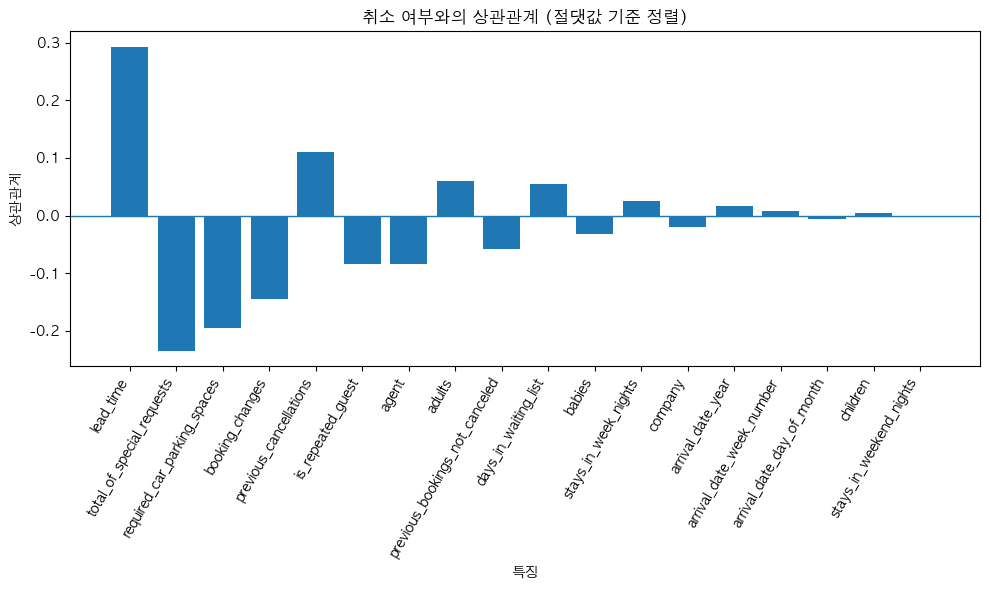

In [110]:
import matplotlib.pyplot as plt
from matplotlib import rc
rc('font', family='AppleGothic')
plt.rcParams['axes.unicode_minus'] = False

# 1) 상관계수 행렬에서 is_canceled와의 상관계수만 추출
target_corr = corr_df['is_canceled'].drop('is_canceled')

# 2) 절대값 기준 정렬
target_corr_sorted = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)

# 3) 막대그래프로 시각화
plt.figure(figsize=(10, 6))
plt.bar(target_corr_sorted.index, target_corr_sorted.values)
plt.title("취소 여부와의 상관관계 (절댓값 기준 정렬)")
plt.xlabel("특징")
plt.ylabel("상관관계")
plt.xticks(rotation=60, ha='right')
plt.axhline(0, linewidth=1)  # 0 기준선
plt.tight_layout()
plt.show()


In [111]:
df.groupby('is_canceled')['lead_time'].agg(['count', 'mean', 'median', 'min', 'max'])


,count,mean,median,min,max
is_canceled,,,,,
0,74872,80.031627,45.0,0,737
1,44115,144.869387,113.0,0,629


#### 3-1) Lead time 분석 ####

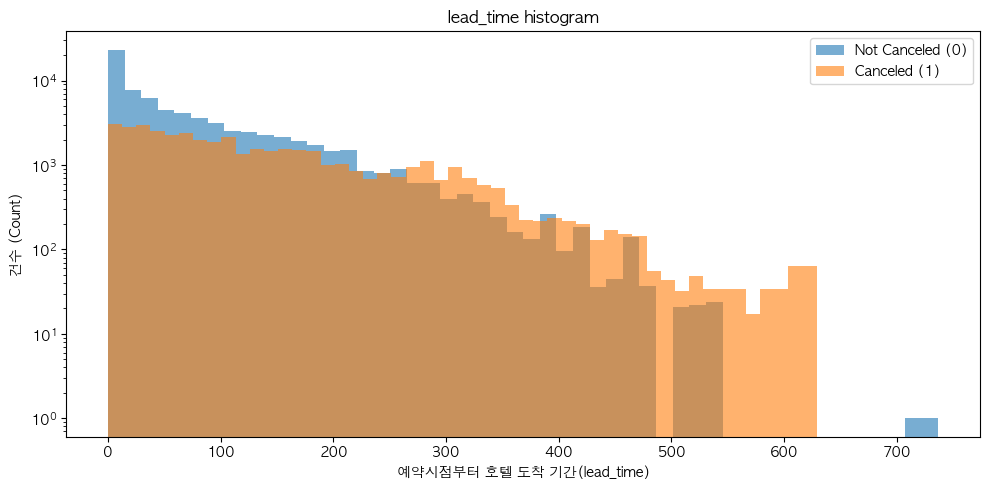

/var/folders/yh/k6gvwz4j64b_y_cmflhq_z240000gn/T/ipykernel_68029/3632984677.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([x0, x1], labels=['Not Canceled (0)', 'Canceled (1)'], showfliers=False)


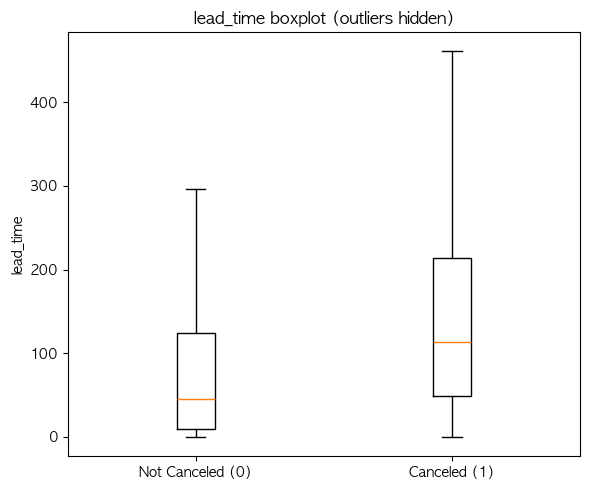

In [114]:
import matplotlib.pyplot as plt

x0 = df[df['is_canceled'] == 0]['lead_time']
x1 = df[df['is_canceled'] == 1]['lead_time']

# 히스토그램(로그 y축: 꼬리 때문에 보기 좋음)
plt.figure(figsize=(10, 5))
plt.hist(x0, bins=50, alpha=0.6, label='Not Canceled (0)')
plt.hist(x1, bins=50, alpha=0.6, label='Canceled (1)')
plt.yscale('log')
plt.title('lead_time histogram')
plt.xlabel('예약시점부터 호텔 도착 기간(lead_time)')
plt.ylabel('건수 (Count)')
plt.legend()
plt.tight_layout()
plt.show()

# 박스플롯(극단값 숨김)
plt.figure(figsize=(6, 5))
plt.boxplot([x0, x1], labels=['Not Canceled (0)', 'Canceled (1)'], showfliers=False)
plt.title('lead_time boxplot (outliers hidden)')
plt.ylabel('lead_time')
plt.tight_layout()
plt.show()


Leadtime 분석 결과

- 취소된 예약의 리드타임(예약~도착까지 기간)이 비취소 예약보다 훨씬 길다.

- 비취소(0)의 평균/중앙값은 약 80일/45일인 반면, 취소(1)는 약 145일/113일로 더 크다.

- 히스토그램과 박스플롯에서도 취소(1) 분포가 더 오른쪽(긴 리드타임)에 치우쳐 있어, 리드타임이 길수록 취소 가능성이 높다는 경향을 확인했다.

#### 3-2) total_of_special_requests 분석 ####

In [ ]:
req_table = df.groupby('total_of_special_requests').agg(
    예약건수=('is_canceled', 'size'),
    취소율=('is_canceled', 'mean')
)

# 취소율 보기 좋게 %로도 추가
req_table['취소율(%)'] = (req_table['취소율'] * 100).round(2)

req_table

,예약건수,취소율,취소율(%)
total_of_special_requests,,,
0,70133,0.477692,47.77
1,33085,0.220190,22.02
2,12911,0.220665,22.07
3,2480,0.177823,17.78
4,338,0.106509,10.65
5,40,0.050000,5.00


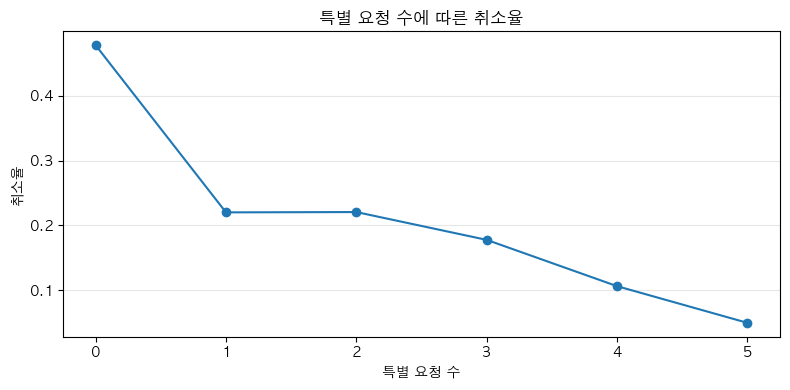

In [117]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(req_table.index, req_table['취소율'], marker='o')
plt.title('특별 요청 수에 따른 취소율')
plt.xlabel('특별 요청 수')
plt.ylabel('취소율')
plt.xticks(req_table.index)  # 눈금이 정수로 보이게
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


total_of_special_requests 분석 결과

- 특별 요청 수가 증가할수록 취소율이 감소했다. 특히 요청이 0개인 예약의 취소율은 47.77%로 매우 높았고, 1~3개 요청이 있는 예약은 약 22%→17.78%로 낮아졌다.

- 이는 특별 요청을 남긴 고객일수록 투숙 의사가 명확하고 예약 확정성이 높다는 신호로 해석할 수 있다(단, 4~5개 구간은 표본 수가 적어 참고용).

#### 3-3) required_car_parking_spaces 분석 ####

In [119]:
parking_table = df.groupby('required_car_parking_spaces').agg(
    예약건수=('is_canceled', 'size'),
    취소율=('is_canceled', 'mean')
)

parking_table['취소율(%)'] = (parking_table['취소율'] * 100).round(2)

parking_table


,예약건수,취소율,취소율(%)
required_car_parking_spaces,,,
0,111580,0.395367,39.54
1,7374,0.000000,0.00
2,28,0.000000,0.00
3,3,0.000000,0.00
8,2,0.000000,0.00


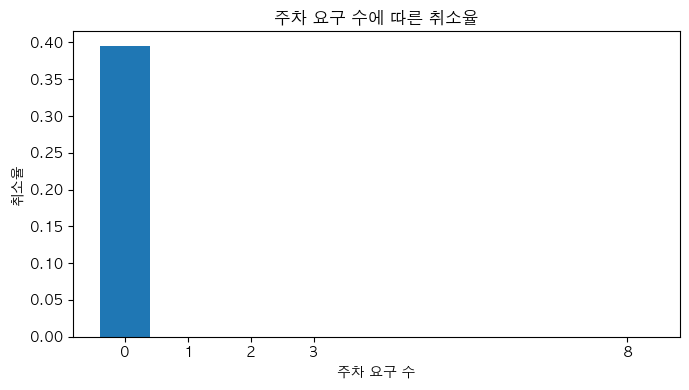

In [120]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.bar(parking_table.index.astype(int), parking_table['취소율'])
plt.title('주차 요구 수에 따른 취소율')
plt.xlabel('주차 요구 수')
plt.ylabel('취소율')
plt.xticks(parking_table.index.astype(int))
plt.tight_layout()
plt.show()


required_car_parking_spaces = 0
- 예약건수 111,580건
- 취소율 39.54%

required_car_parking_spaces = 1
- 예약건수 7,374건
- 취소율 0% 로 나옴

required_car_parking_spaces 분석 결과
- 주차를 요청한 고객은 차량 이동이 확정되어 있고, 계획이 구체적이라 취소 가능성이 낮을 수 있음.

- 주차 요구 수가 0인 예약이 대부분(111,580건)이며 취소율은 39.54%였다. 반면 주차 1건 이상 요구한 예약은 표본이 상대적으로 적고(1건 7,374건), 취소율이 0%로 나타났다.

#### 3-4) booking_changes 분석 ####

In [ ]:
df['변경여부'] = (df['booking_changes'] > 0).astype(int)

change_table = df.groupby('변경여부').agg(
    예약건수=('is_canceled', 'size'),
    취소율=('is_canceled', 'mean')
)

change_table['취소율(%)'] = (change_table['취소율'] * 100).round(2)

# 보기 좋게 인덱스 이름 바꾸기
change_table.index = ['변경 없음(0)', '변경 있음(1+)']

change_table

,예약건수,취소율,취소율(%)
변경 없음(0),101066,0.408624,40.86
변경 있음(1+),17921,0.157190,15.72


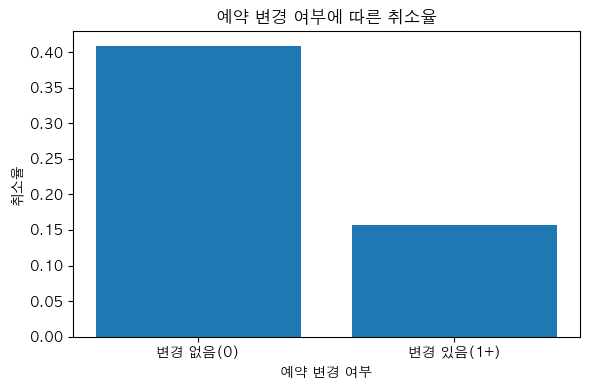

In [124]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.bar(change_table.index, change_table['취소율'])
plt.title('예약 변경 여부에 따른 취소율')
plt.xlabel('예약 변경 여부')
plt.ylabel('취소율')
plt.tight_layout()
plt.show()

booking_changes 분석 결과

- 예약 변경 여부에 따라 취소율이 크게 달랐다. 변경이 없는 예약(0)의 취소율은 40.86%인 반면, 변경이 한 번 이상 있었던 예약(1+)은 15.72%로 훨씬 낮았다.

- 즉, 예약 변경은 취소의 전조라기보다는 ‘예약을 유지하려는 조정 행동’으로 해석될 가능성이 있으며, 취소율을 낮추는 신호로도 볼 수 있다.

#### 3-5) previous_cancellations 분석 ####

In [ ]:
df['이전취소이력'] = (df['previous_cancellations'] > 0).astype(int)

prev_table = df.groupby('이전취소이력').agg(
    예약건수=('is_canceled', 'size'),
    취소율=('is_canceled', 'mean')
)

prev_table['취소율(%)'] = (prev_table['취소율'] * 100).round(2)

prev_table.index = ['이전 취소 없음(0)', '이전 취소 있음(1+)']

prev_table

,예약건수,취소율,취소율(%)
이전 취소 없음(0),112510,0.339321,33.93
이전 취소 있음(1+),6477,0.916782,91.68


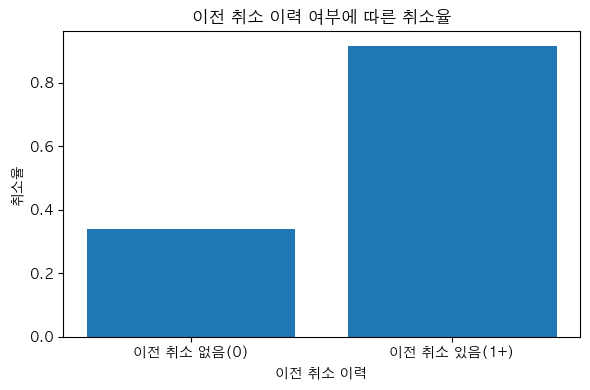

In [126]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.bar(prev_table.index, prev_table['취소율'])
plt.title('이전 취소 이력 여부에 따른 취소율')
plt.xlabel('이전 취소 이력')
plt.ylabel('취소율')
plt.tight_layout()
plt.show()

previous_cancellations 분석결과

- 이전 취소 이력(previous_cancellations)은 취소 여부와 매우 강한 연관을 보였다. 이전 취소 이력이 없는 고객의 취소율은 33.93%였으나, 이전 취소 이력이 있는 고객(1+)의 취소율은 91.68%로 급증했다.

- 따라서 과거 취소 경험은 ‘고위험 취소 고객’ 식별에 유효한 핵심 변수로 판단된다.

## 4. 분석 결과 요약 ##

### 1) 취소율이 높은 주요 집단 ###

- 리드타임(lead_time)이 긴 예약 고객

    - 취소(1)의 평균/중앙값이 비취소(0)보다 크게 높음(약 145일/113일 vs 80일/45일).

    - “미리 잡아두는 예약”일수록 취소가 많이 발생하는 그룹.

- 이전 취소 이력이 있는 고객(previous_cancellations > 0)

    - 취소율이 **91.68%**로 매우 높음(이력 없음 33.93% 대비 압도적).

    - 반복 취소 성향이 강한 “고위험 고객군”으로 볼 수 있음.

- 특별 요청이 없는 고객(total_of_special_requests = 0)

    - 취소율이 **47.77%**로 가장 높음(요청이 1개만 있어도 22%대로 급감).

### 2) 취소를 유발하는 핵심 조건(핵심 트리거) ###

- 계획이 덜 확정된 예약”의 공통 특징

    - 리드타임이 길고(일정이 멀다)

    - 특별 요청이 없고(구체 니즈/확정 의지가 없다)

    - 과거 취소 이력이 있으면(행동 패턴) 거의 다시 취소로 이어짐

    -> 즉, 취소는 단일 변수보다‘확정성  낮음’ 시그널의 결합에서 강해지는 경향이 있음.

### 3) 취소율이 낮은 안정적인 고객 성향 ###

- 특별 요청이 많은 고객

    - 요청 수가 0→5로 갈수록 취소율이 **47.77% → 5%**로 꾸준히 감소.

    - 요청을 남긴 고객은 “투숙 의지/계획 구체성”이 높을 가능성.

- 예약 변경이 있었던 고객(booking_changes > 0)

    - 변경 없음 취소율 40.86%, 변경 있음 15.72%

    - 변경 = 불안이 아니라, 실제로는 취소 대신 조정(유지)하는 고객일 가능성이 큼.

- 주차 요구가 있는 고객(required_car_parking_spaces ≥ 1)

    - 데이터상 취소율이 0%로 나와 “확정성” 신호로 보이지만,

    - 0%는 비정상적으로 완벽해서 데이터 기록 규칙 영향 가능성을 염두(해석은 보조적으로).

### 4) 가장 위험한 예약 조합(리스크가 가장 큰 패턴) ###


- previous_cancellations > 0 (이전 취소 이력 있음)

    - lead_time이 김(멀리 예약)

    - total_of_special_requests = 0 (요청 없음)

    - booking_changes = 0 (변경 없음)

### 5) 취소율을 개선하기 위한 방향 ###

A. 고위험 고객(이전 취소 이력) 사전 관리

- 이전 취소 이력(1+) 고객을 ‘고위험’으로 태깅

- 리드타임이 긴 경우엔 특히 무료취소 기한 단축, 보증금/카드 보증 강화, 리마인드 메시지 강화 등으로 관리

B. “요청 없음(0)” 예약의 확정성 끌어올리기

- 예약 직후/도착 임박 시점에 “요청사항 선택(없음/있음)”을 유도

ex) 객실 선호(고층/트윈/뷰), 체크인 시간, 아기침대 등

- 요청을 받는 것이 목적이 아니라, 고객이 계획을 확정하게 만드는 장치로 활용

C. 취소 대신 “변경(조정)”으로 유도하는 UX/정책

- booking_changes가 있는 고객은 취소율이 낮았음 → “조정 경로”가 중요

- 일정 변경/인원 변경을 쉽게 제공하고,

- “취소” 대신 “변경”을 선택하도록 옵션을 전면에 배치(특히 리드타임 긴 예약)

D. 리드타임 긴 예약에 대한 단계별 확정 프로세스

- 장기 예약은 취소 위험이 높으니

    - 도착 30일/14일/7일 전 확인 메시지

    - 확정 응답 유도(간단 버튼/링크)

    - 무응답 지속 시 조건 재안내(취소정책, 보증금 등)